In [4]:
import matplotlib.pyplot as plt

from poset import PoSet
from simplicial_complex import SimplicialComplex

# Partially Ordered Set (PoSet)

- Set, $S$
- Binary relation $R$, $\preceq$
  - $(a,b) \in R$

- all elements $x, y, z \in S$:
    - Reflexive: $(x,x) \in R$
    <br>
    - Anti-Symmetry: If $(x,y), (y,x) \in R$, then $x = y$
    <br>
    - Transitivity: If $(x,y), (y,z) \in R$ then $(x,z) \in R$

_Partial_ $\implies$ not all pairs are comparable.

**Example (below)**

Let R be the relation $\subseteq$, so below we then have p = (S,$\subseteq$).

Note: ((1,), (2,)) is not in R. Neither element is subset of each other so 
it will not be in R. This is what partial ordering allows.

In [6]:
p = PoSet(
    S = {(1,), (2,), (1,2), (1,2,3)}, 
    R = {
        ((1,),(1,)),
        ((2,),(2,)), 
        ((1,2),(1,2)), 
        ((1,),(1,2)), 
        ((2,),(1,2)),
        ((1,2,3), (1,2,3))
    }
)

print("The relation R on S is the set:")
print(*p.format_relation(), sep="\n")

The relation R on S is the set:
((1,),(1,))
((1,),(1, 2))
((1, 2),(1, 2))
((1, 2, 3),(1, 2, 3))
((2,),(1, 2))
((2,),(2,))


**Examples of bad PoSets, and error handling**

Use `#` to show errors

In [ ]:
%%script false --no-raise-error
p_not_reflexive = PoSet(
    S = {1,2,3}, 
    R = {(1,1), (2,2), (1,2), (2,1)},
)

In [ ]:
%%script false --no-raise-error
p_not_antisymmetric = PoSet(S = {1,2,3}, 
    R = {(1,1), (2,2), (3,3), (1,2), (2,1)},
)

In [ ]:
%%script false --no-raise-error
p_not_transative = PoSet(
    S = {1,2,3}, 
    R = {(1,1), (2,2), (3,3), (1,2), (2,3)},
)

# Simplicial Complex (Abstract)

> Finite collection, $K$, of non-empty sets such that for all 
> $\sigma \in K$ and all non-empty $\tau \subseteq \sigma$, $\tau \in K$.

Each set, $\sigma$, in $K$ is called a simplex.

### Why a subclass?

#### Methods
- n-simplex
- Faces
- Maximal
- Hasse Diagrams
- Dimension
- Connected
- Boundary
- Euler Characteristic
- Surface
- Orientable


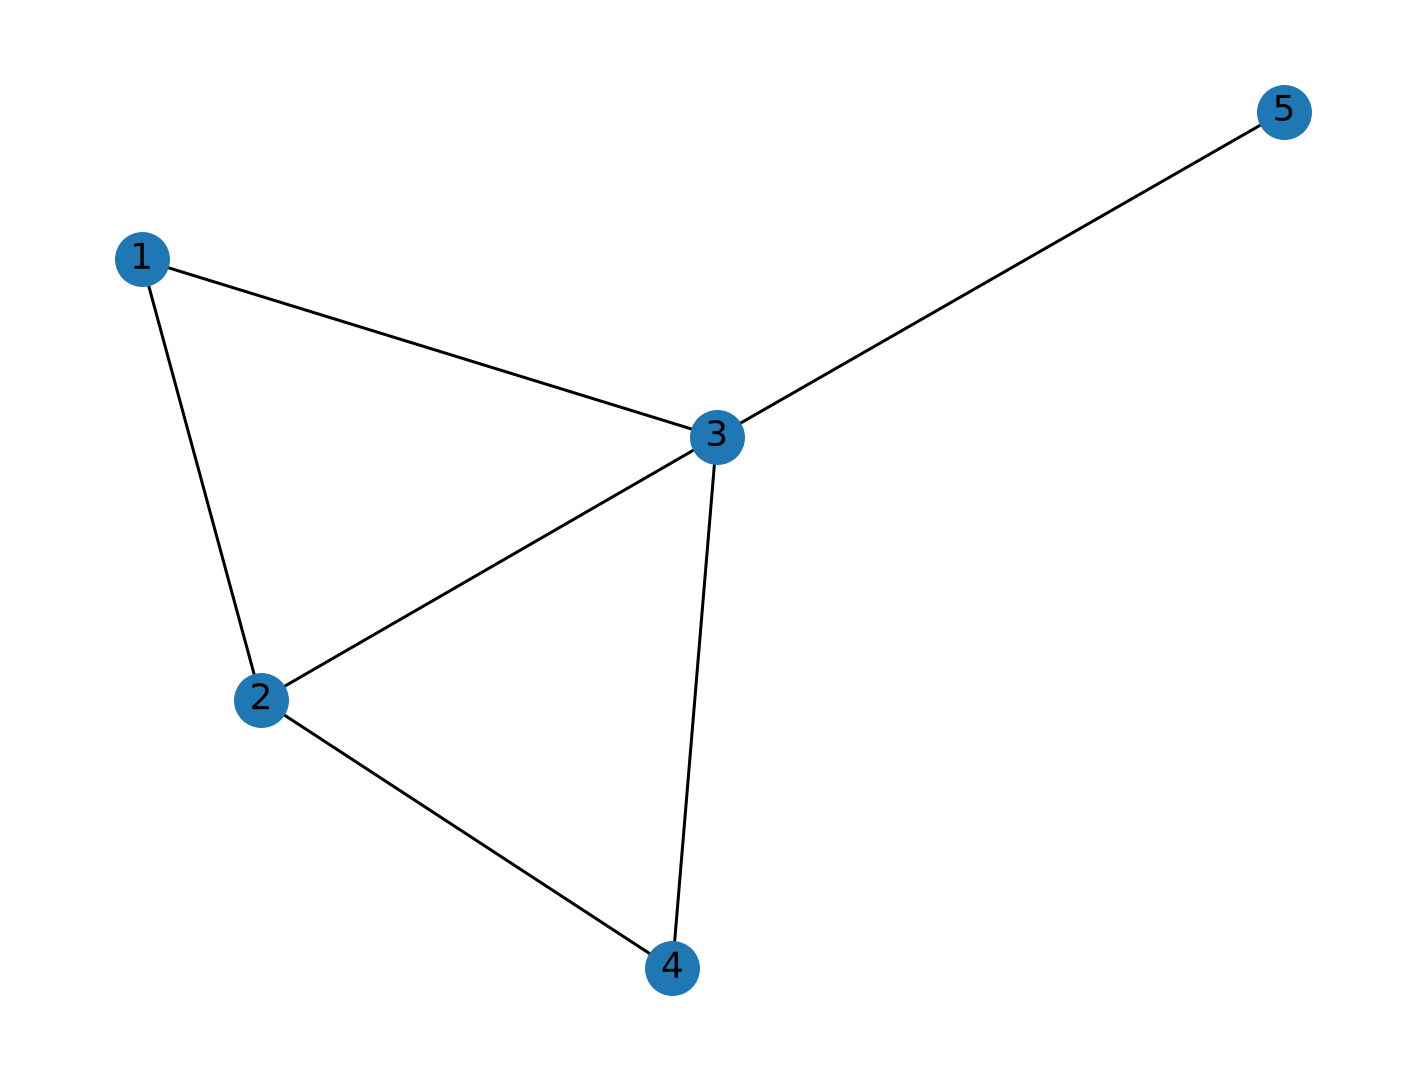

In [8]:
# Two Triangles and a Tail Example
two_triangles = SimplicialComplex([(1,2,3),(2,3,4),(3,5)])
#print(*sorted(two_triangles.S, key=lambda f: len(f)), sep="\n")
#print(*sorted(two_triangles.R), sep="\n")
two_triangles.s_complex_graph()

### **n-Simplex, Faces, and Maximal**

_n-Simplex_:

- 0-Simplex - Point
- 1-Simplex - Line Segment/Edge
- 2-Simplex - Triangle
- 3-Simplex - Tetrahedron

_Faces_

> $\tau$ is called a face $\sigma \in K$ if $\tau \subseteq \sigma$.

_Maximal_

> We call a simplex $\sigma \in K$ maximal if it is not a face of another
simplex in $K$.

### Hasse Diagrams
Diagrams that show the relationship between our elements of S under our relation R.

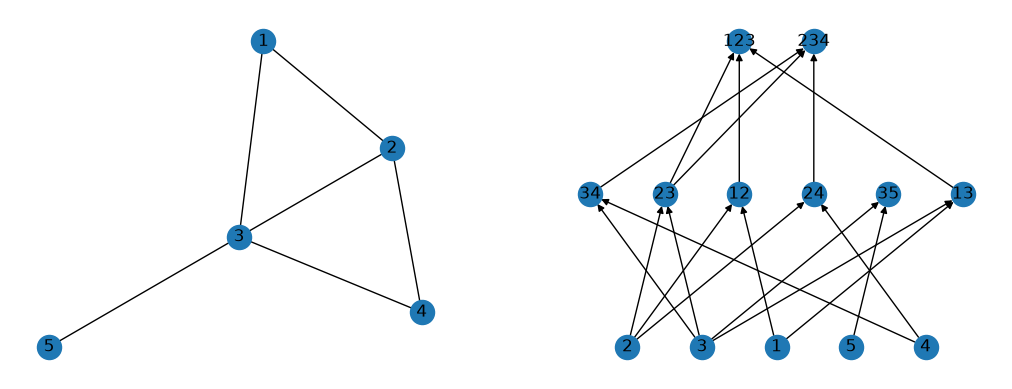

In [104]:
plt.figure(figsize=(12.8, 4.8))

plt.subplot(1,2,1)
two_triangles.s_complex_graph()

plt.subplot(1,2,2)
two_triangles.draw_hasse()

plt.show()

## **Dimension, Connected, Euler Characteristic**

### Dimension
$\dim(\sigma) = \lvert\sigma\rvert - 1$

$\dim(K) = \max\{\dim(\sigma) : \sigma \in K\}$

### Connected
$K$ is connected if any two 0-simplices can be joined by a path of 1-simplices in $K$.

### Euler Characteristic

- Topological Invarient (i.e. the number doesn't change under deformations)

$\chi(K) = \sum_{i=0}^{\dim(K)} (-1)^{i} s_{i}$, where $s_{i}$ is the number of $i$-simplices in $K$.

V-E+F = $\chi$


S = {{0}, {1}, {2}, {3}, {0, 1}, {0, 2}, {0, 3}, {1, 2}, {1, 3}, {2, 3}, {0, 1, 2}, {0, 1, 3}, {0, 2, 3}, {1, 2, 3}}

Dim: 2
Connected: True
Number of 0-simplices: 4
Number of 1-simplices: 6
Number of 2-simplices: 4
Euler Characteristic: 2


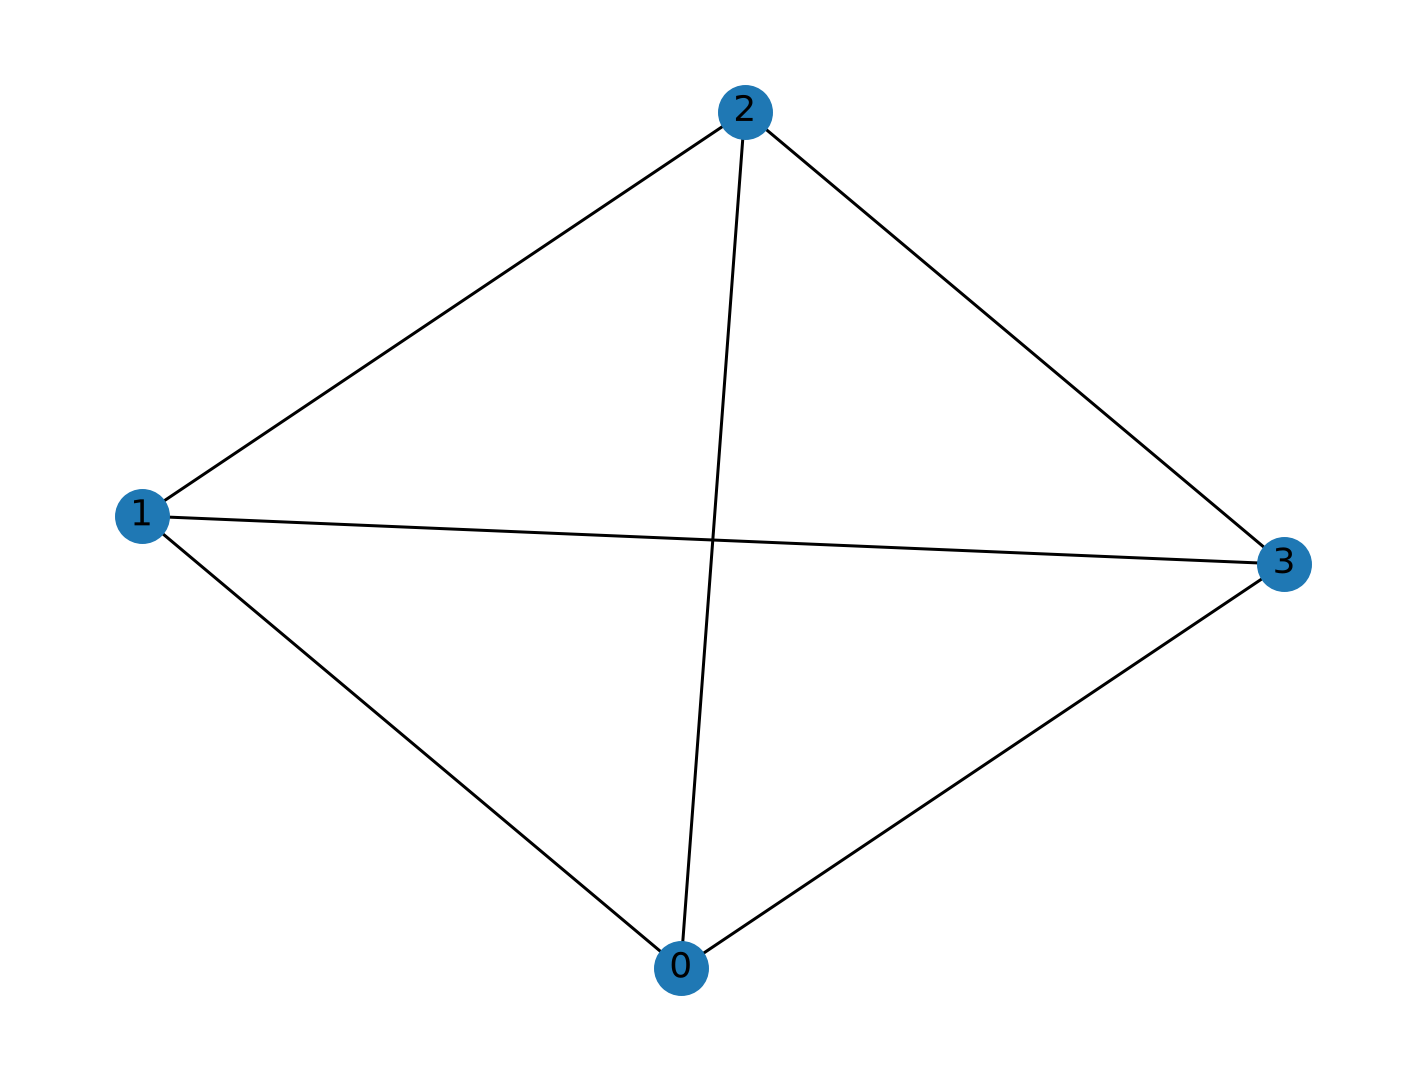

In [9]:
# Simple Examples
web = SimplicialComplex([(0,1,2),(0,2,3),(0,3,4),(0,4,5), (0,5,6), (0,6,1)])
tetrahedron = SimplicialComplex([(0,1,2),(0,2,3),(0,3,1),(1,2,3)])

def info(complex):
    print(f"{complex}\n")

    print(f"Dim: {complex.dim_k()}")
    print(f"Connected: {complex.is_connected()}")

    for n in range(complex.dim_k()+1):
        print(f"Number of {n}-simplices: {len(complex.n_simplices(n))}")

    print(f"Euler Characteristic: {complex.euler_characteristic()}")
    complex.s_complex_graph()


#info(web)
info(tetrahedron)

## Boundary

> $bd(\sigma) = \sigma - \operatorname{int}(\sigma)$

- $\operatorname{int}(\sigma)$ is the _Interior_ of a simplex.
- Hasse diagram is useful because we can look "one-level-down" and see interior = shared edge.

Boundary web: ['{1, 2}', '{5, 6}', '{3, 4}', '{1, 6}', '{4, 5}', '{2, 3}']

Boundary of two_triangles: ['{5}', '{1, 2}', '{1, 3}', '{3, 4}', '{2, 4}']

Boundary of tetrahedron: []



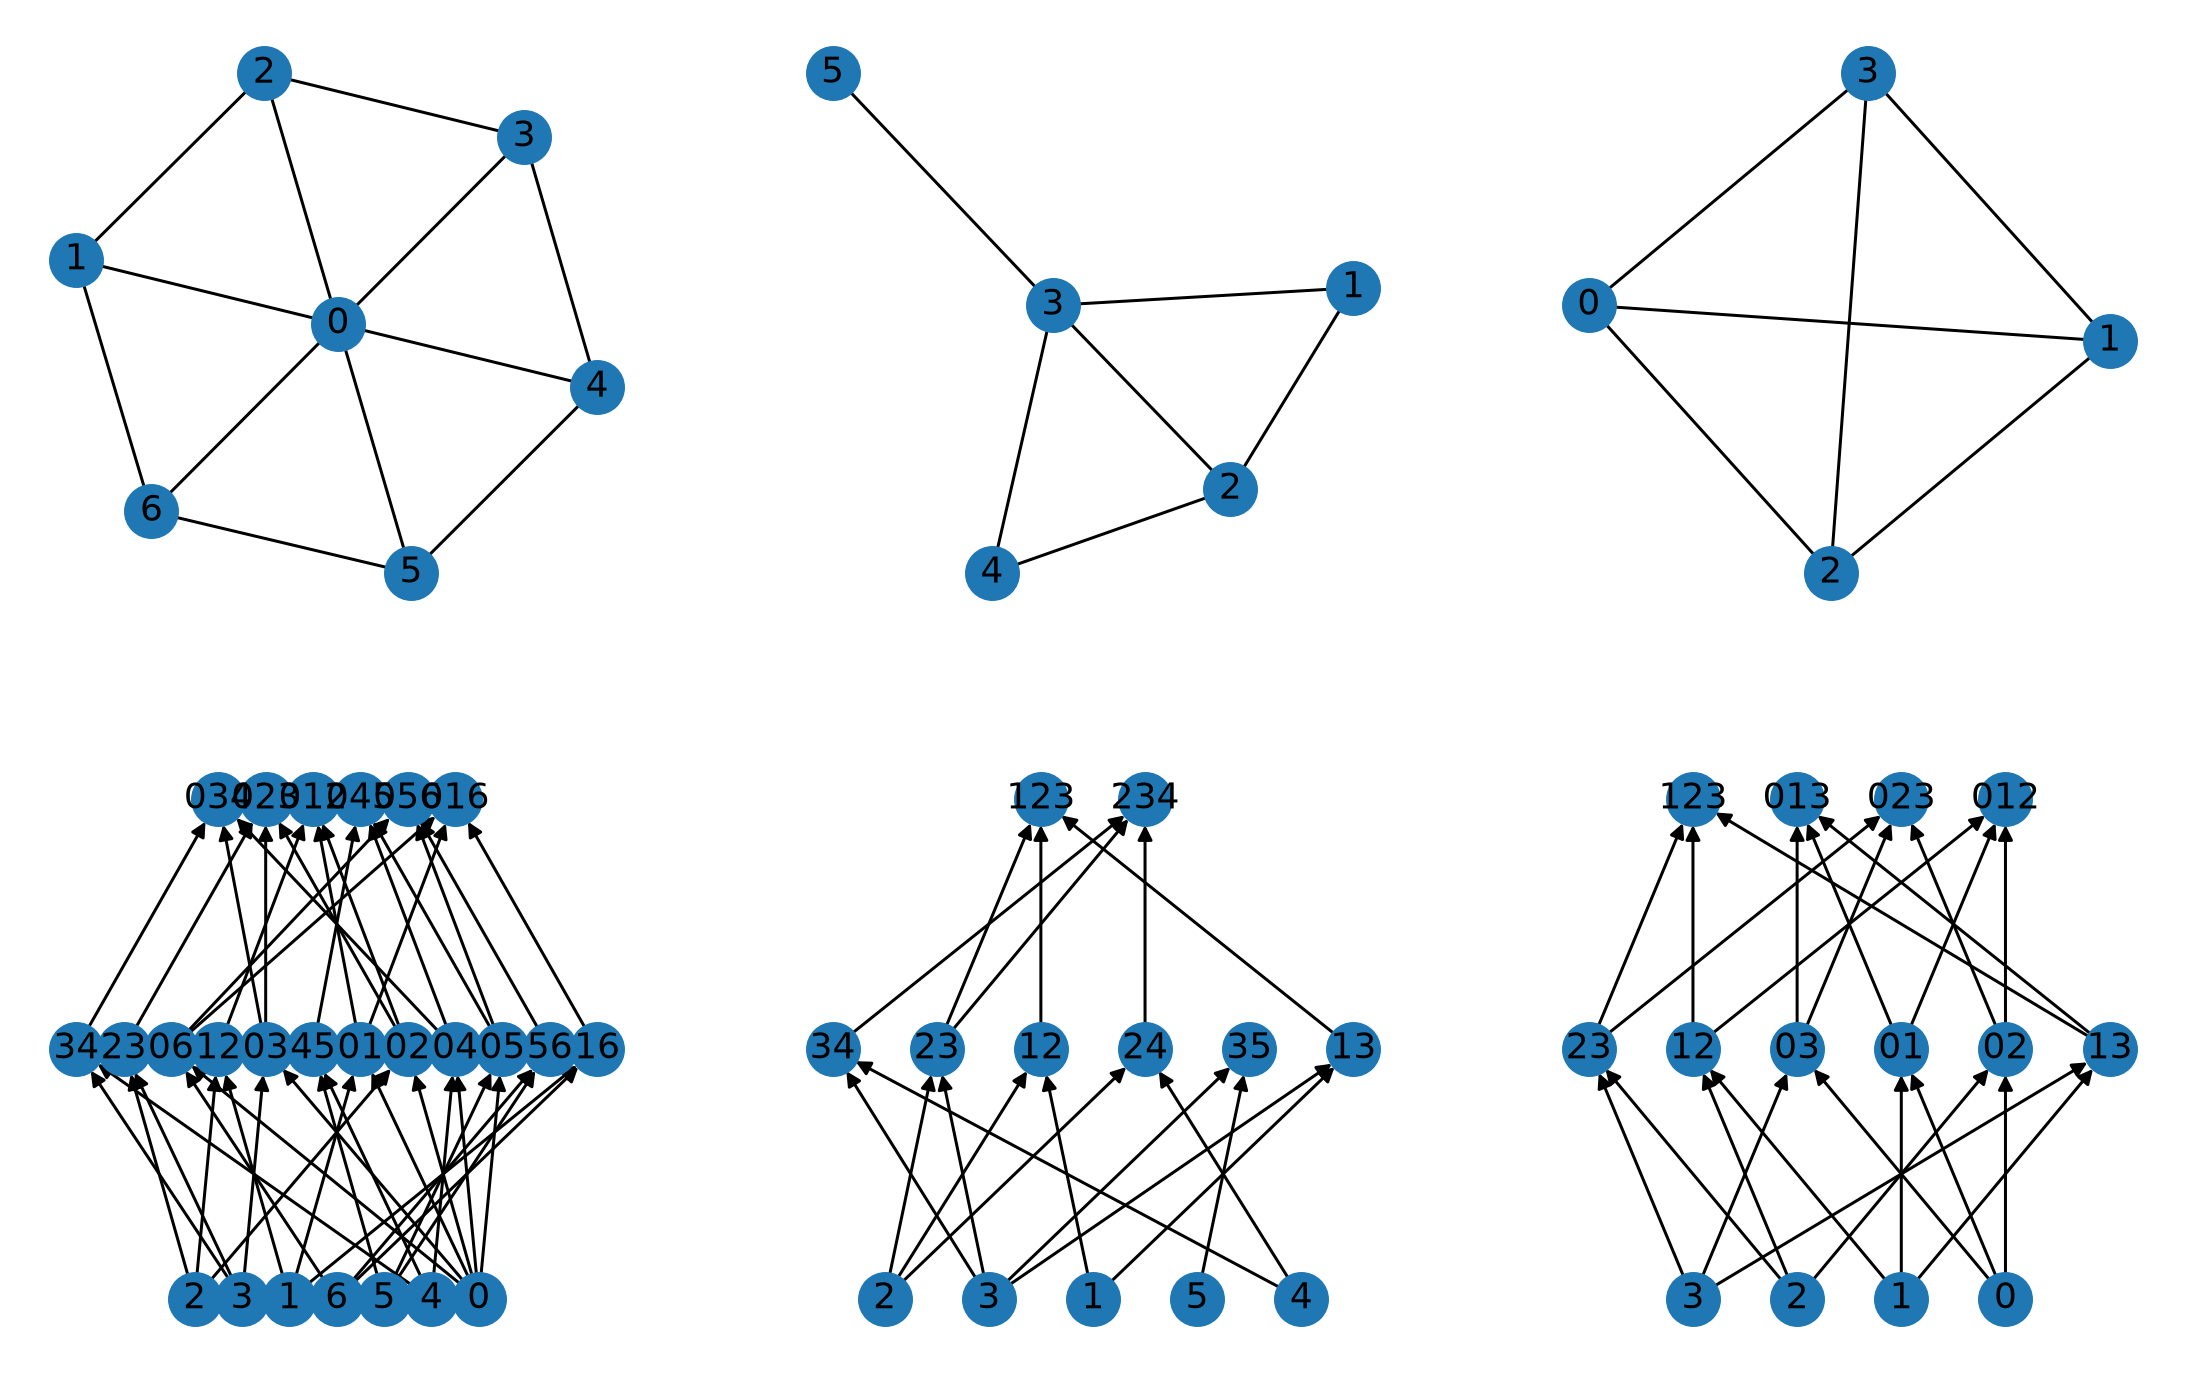

In [10]:
print(f"Boundary web: {web.boundary_k()}\n")
print(f"Boundary of two_triangles: {two_triangles.boundary_k()}\n")
print(f"Boundary of tetrahedron: {tetrahedron.boundary_k()}\n")

plt.figure(figsize=(12.8, 8))

plt.subplot(2,3,1)
web.s_complex_graph()
plt.subplot(2,3,4)
web.draw_hasse()

plt.subplot(2,3,2)
two_triangles.s_complex_graph()
plt.subplot(2,3,5)
two_triangles.draw_hasse()

plt.subplot(2,3,3)
tetrahedron.s_complex_graph()
plt.subplot(2,3,6)
tetrahedron.draw_hasse()

plt.show()


## Surface: 2-Manifold (Closed)

1. Every maximal simplex is a 2-simplex.
2. $\forall v \in K$, $\exists\, \sigma \in K$ such that $v \in \sigma$ and $\sigma$ is maximal.
3. Every 1-simplex is contained in exactly two, 2-simplices.
4. Vertex condition (not yet implemented)

### Ant's that never fall off!

![Sphere](250px-Sphere_(Shaded).png)
![3-D Releaux Triangle](screeshotreauleauxtriangle.webp)
![Tetrahedron](250px-Tetrahedron_Petrie_polygon.png)

Source(s): 
- [Sphere - Wikimedia Commons](https://upload.wikimedia.org/wikipedia/commons/3/3d/Sphere_%28Shaded%29.png)
- [Releaux Triangle](https://media.printables.com/media/prints/f9ab8bd4-b7bf-4e50-a77b-13ea883bc702/images/9393272_64773120-3c5d-40d6-bb65-2e9c30bb6344_a08c895f-e7e0-4a06-84c4-8df33c60bdaf/thumbs/inside/320x240/png/screeshotreauleauxtriangle.webp)
- [Tetrahedron - Wikimedia Commons](https://upload.wikimedia.org/wikipedia/commons/7/7e/Tetrahedron_Petrie_polygon.png)

Tetrehedron is Surface?: True
Web is Surface?: False


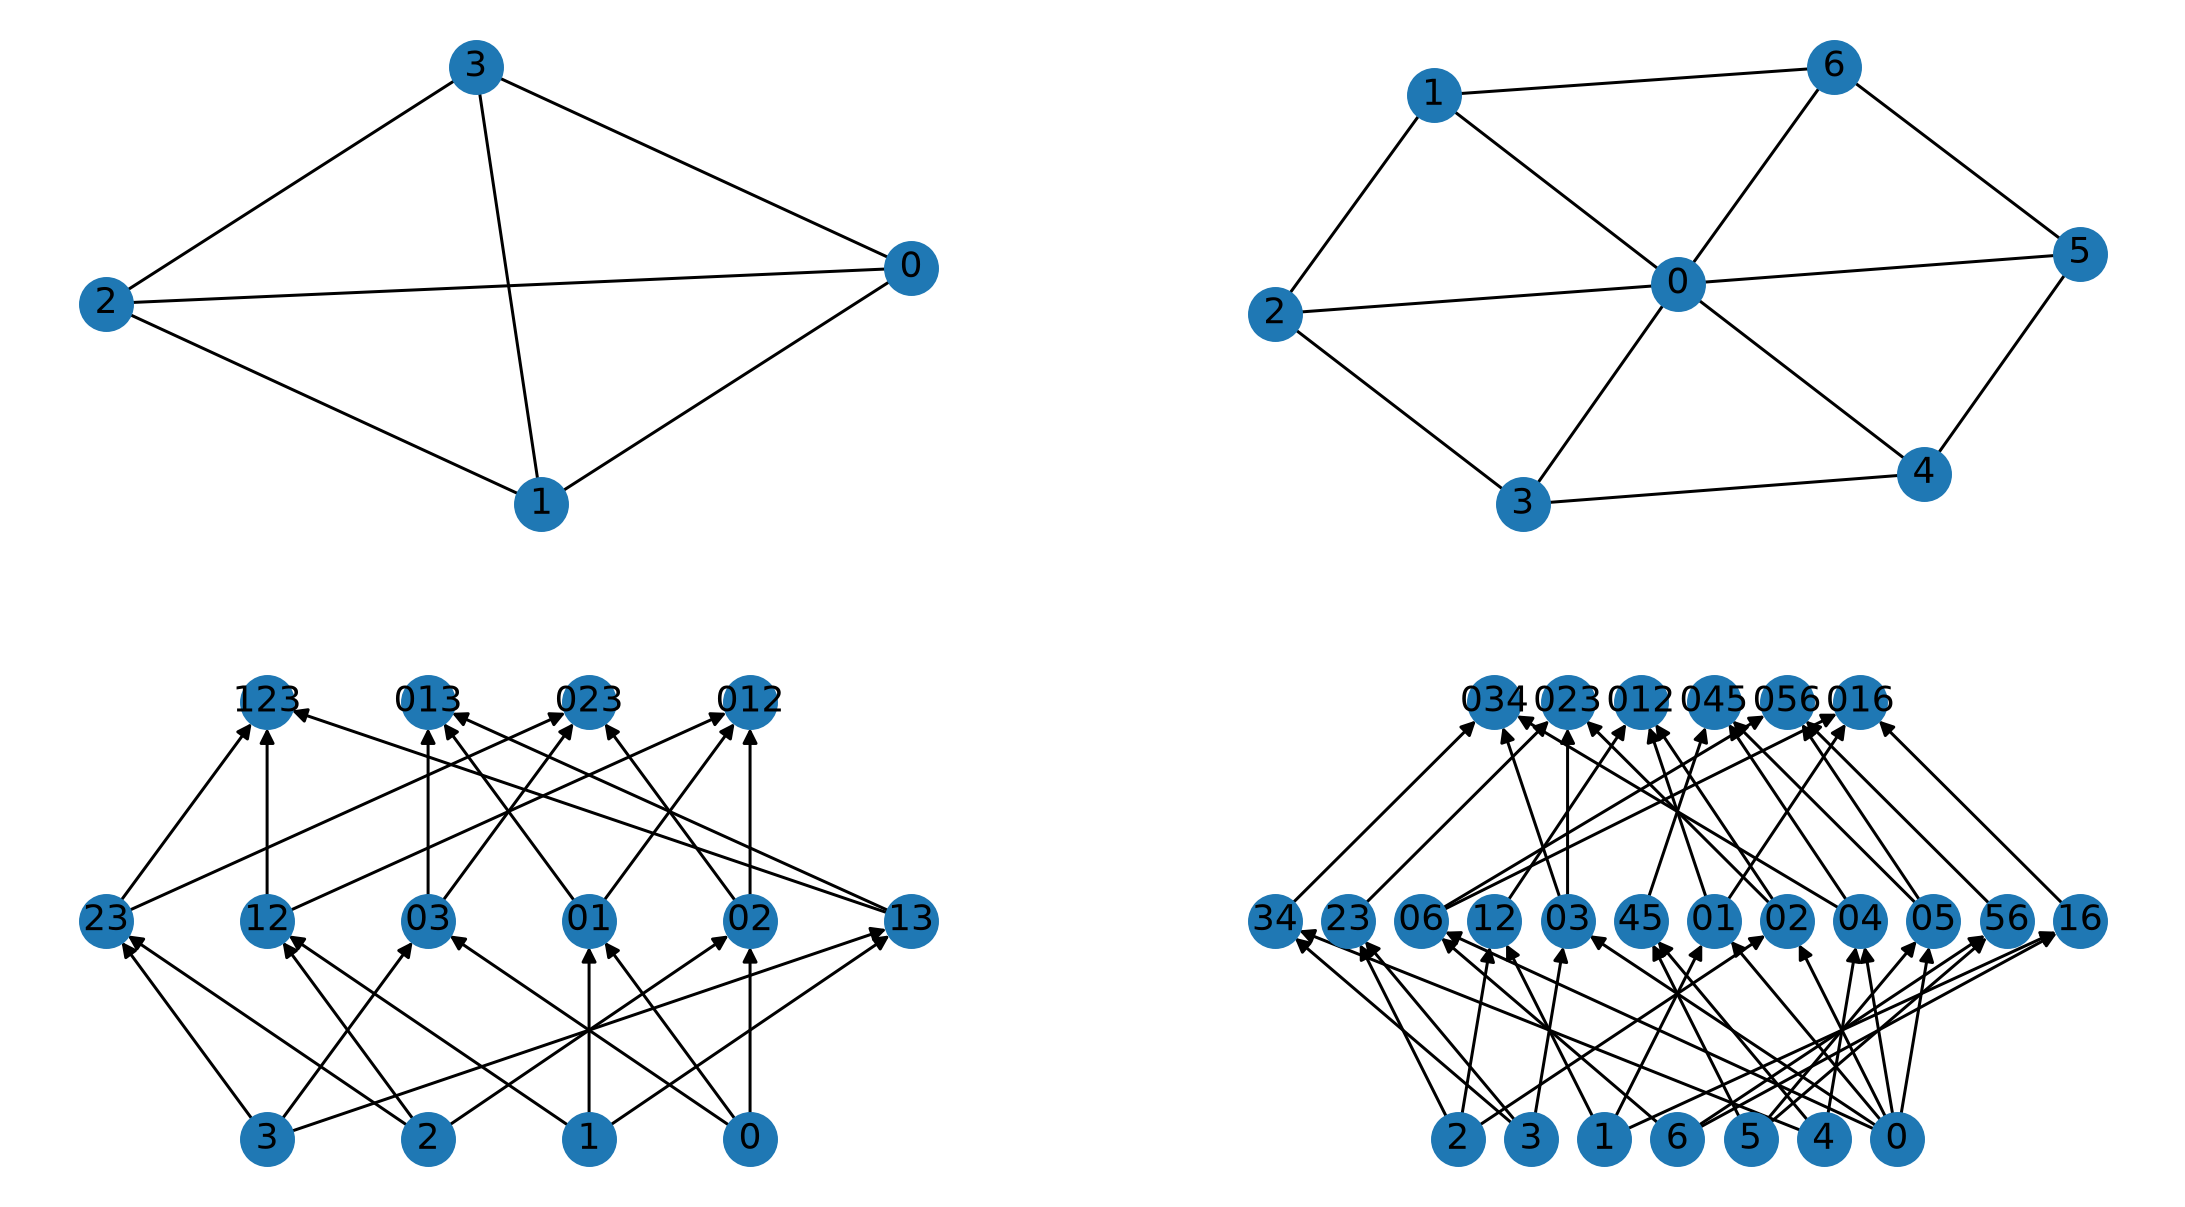

In [ ]:
plt.figure(figsize=(12.8, 7))

#Tetrahedron/Sphere
tetrahedron = SimplicialComplex([(0,1,2),(0,2,3),(0,3,1),(1,2,3)])
print(f"Tetrehedron is Surface?: {tetrahedron.is_surface()}")
plt.subplot(2,2,1)
tetrahedron.s_complex_graph()
plt.subplot(2,2,3)
tetrahedron.draw_hasse()

# Web
web = SimplicialComplex([(0,1,2),(0,2,3),(0,3,4),(0,4,5), (0,5,6), (0,6,1)])
print(f"Web is Surface?: {web.is_surface()}")
plt.subplot(2,2,2)
web.s_complex_graph()
plt.subplot(2,2,4)
web.draw_hasse()

plt.show()

## Orientable

![Möbius strip](Flipping_in_Möbius_strip.gif) ![Tetrahedron](250px-Tetrahedron_Petrie_polygon.png)

Mobius Strip (left) and Tetrahedron (right)



![2-Simplex Orientation](2-simplex-orientation.png)

### General Steps
1. Grab a simplex add to list of `checked orientation`.
2. Get simplex's edges and checked if they are shared, if so check if neighbor's orientation is correct and add `checked orientation` if it is.
3. If we find that a neighbor has been checked already and has orientation differnt that the one stored --> not orientable.

![Mobius Simplical Complex](mobius5_complex.svg)


Source: 
- [Flipping Mobius Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Flipping_in_M%C3%B6bius_strip.gif)
- [Tetrahedron - Wikimedia Commons](https://upload.wikimedia.org/wikipedia/commons/7/7e/Tetrahedron_Petrie_polygon.png)
- [Mobius Simplicial Complex Diagram - Claude (Opus 5.5)](https://claude.ai/)

In [109]:
# Modified is_orientable() to show how it checks
%run display_orientable.py

Starting Simplex: frozenset({0, 1, 2})
Orientaion Passed, added: (0, 4, 1)
Orientaion Passed, added: (1, 3, 2)
Orientaion Passed, added: (2, 3, 4)
Orientaion Passed, added: (0, 4, 3)


Checked:
(0, 1, 2)
(0, 4, 1)
(1, 3, 2)
(2, 3, 4)
(0, 4, 3)


Old Orientation: 1
(0, 4, 1)
New Orientation: 2
(0, 1, 4)


Not Orientable


In [13]:
mobius = SimplicialComplex([
    (0, 1, 2),
    (1, 2, 3),
    (2, 3, 4),
    (3, 4, 0),
    (4, 0, 1),
])

print(f"Tetrahedron Orientable?: {tetrahedron.is_orientable()}")
print(f"Mobius Strip Orientable?: {mobius.is_orientable()}")

Tetrahedron Orientable?: True
Mobius Strip Orientable?: False


# Related Comic

![Calvin's Transmogrifier](calvin-and-hobbes-transmogrifier.avif)

*Calvin and Hobbes* © Bill Watterson, March 28, 1987. Source: [GoComics](https://www.gocomics.com/calvinandhobbes/1987/03/28)


# References

- Edelsbrunner, H., & Harer, J. L. (2010). *Computational Topology: An Introduction*. American Mathematical Society. ISBN 978-0-8218-4925-5.
- Rabadán, R., & Blumberg, A. J. (2019). *Topological Data Analysis for Genomics and Evolution: Topology in Biology*. Cambridge University Press. ISBN 978-1-107-15954-9.
- Wildberger, N. J. (n.d.). *Insights into Mathematics* [YouTube channel]. YouTube. Retrieved November 2, 2026, from https://www.youtube.com/@njwildberger

### AI Use Statement

Claude (Opus 5.5) was used to: help check code and create Mobius diagram, present examples of coding or markdown language, help cross-check concepts, and format references.